# Minimap 02 – Van detecties naar een 2D-minimapvideo

Dit notebook maakt de eindvideo: links de clip met boxen en de geprojecteerde veldlijnen, rechts een
**2D-minimap van bovenaf** met de spelers, de bal en zijn spoor, en bovenaan een **infobalk** per frame.

**De pijplijn:**

```
frames ──► 1. YOLO-detectie ──► 2. dubbele boxen weg ──► 3. tracking (ByteTrack) + team per speler
                                                                     │
keypoints.json ──► homografie H per frame ──► 4. voeten → meters op het veld
                                                                     │
                     5. bal: kandidaten filteren + Kalman-filter ◄───┘
                                         │
                     6. balbezit ──► 7. video + csv + samenvatting
```

**Voorwaarden**
- `01_keypoints.md`: de veldpunten zijn aangeklikt (`keypoints.json`).
- `../02_model.ipynb`: het getrainde model, geëxporteerd naar OpenVINO (sectie 10). Bestaat dat nog niet, dan
  gebruikt dit notebook het model van Brent (`kobe/homography/pretrained/best_openvino_model`).
- Kernel: de gewone `venv` (met `openvino` en `lap`). De detectie draait via OpenVINO op de Intel Arc GPU.

In [1]:
import csv
import json
import re
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from ultralytics import YOLO

from homography import Homographies
from pitch import FRAMES_DIR, KEYPOINTS, LENGTH, OUTPUT_DIR, REPO_ROOT, WIDTH
from render import COLOURS, FPS, MINIMAP, label, mini_px, render_frame
from tracking import stable_possession, track_ball, track_people, vote_groups

## Instellingen

| Instelling | Waarde | Waarom |
|---|---|---|
| `DETECT_CONF` | 0.1 | alles boven 0,1 bewaren: de tracker gebruikt ook zwakke boxen om een bestaande speler te blijven volgen |
| `PERSON_CONF` | 0.3 | een **nieuwe** speler-track begint pas bij 0,3 (minder spookspelers) |
| `BALL_CONF` | 0.1 | de bal is klein en onzeker: lage drempel, de Kalman-filter ruimt valse kandidaten op |
| `BALL_START` | 0.12 (eigen) / 0.25 (Brent) | zekerheid nodig om een **nieuwe** baltrack te starten. Ons model geeft de bal nooit meer dan ±0,2, maar die zwakke detecties liggen bijna altijd juist |
| `MAX_BALL_SIZE` | 40 px | een "bal" groter dan 40 px is iets anders (hoofd, reclamebord) |
| `SPOT_RADIUS` | 1 m | de geschilderde middenstip en strafschopstippen lijken op een bal |
| `DUPLICATE_IOU` | 0.6 | twee boxen die zoveel overlappen zijn dezelfde persoon |
| `POSSESSION_RADIUS` | 2 m | de dichtste speler binnen 2 m van de bal "heeft" de bal |
| `PITCH_MARGIN` | 3 m | wie meer dan 3 m buiten de lijnen staat (bank, ballenjongens) telt niet mee |

In [2]:
NB_DIR = Path.cwd()                                    # kobe/notebooks/minimap/
own_model = NB_DIR.parent / "runs" / "yolo26l_1920" / "weights" / "best_openvino_model"
brent_model = REPO_ROOT / "kobe" / "homography" / "pretrained" / "best_openvino_model"
brent_v2_model = REPO_ROOT / "kobe" / "homography" / "pretrained" / "brent_v2" / "best_openvino_model"  # Brent's newer model (9 Nov)
USE_MODEL = "brent_v2"     # "own" (runs/yolo26l_1920), "brent" or "brent_v2"
WEIGHTS = {"own": own_model, "brent": brent_model, "brent_v2": brent_v2_model}[USE_MODEL]
if not WEIGHTS.exists():
    WEIGHTS, USE_MODEL = brent_model, "brent"
DEVICE = "intel:gpu"   # OpenVINO on the Intel Arc GPU ("intel:cpu" also works, slower)
# The image size the model was exported with is stored next to it
IMGSZ = yaml.safe_load((WEIGHTS / "metadata.yaml").read_text())["imgsz"][0]

DETECT_CONF, PERSON_CONF, BALL_CONF = 0.1, 0.3, 0.1
MAX_BALL_SIZE = 40
SPOTS = [KEYPOINTS[n] for n in ("centre", "L_penalty_spot", "R_penalty_spot")]
SPOT_RADIUS = 1.0
DUPLICATE_IOU = 0.6
POSSESSION_RADIUS = 2.0
PITCH_MARGIN = 3.0
MAX_BALL_GAP = 15      # frames (0.5 s) of missing ball that are interpolated
# Confidence a ball needs to start a ball track. Our yolo26l_1920 never gives the ball more than ~0.2,
# but those weak detections are almost always in the right place (see the check below)
BALL_START = {"own": 0.12, "brent": 0.25, "brent_v2": 0.25}[USE_MODEL]

RUN = WEIGHTS.parent.parent.name if WEIGHTS == own_model else USE_MODEL
OUTPUT_DIR.mkdir(exist_ok=True)
frames = sorted(FRAMES_DIR.glob("*.jpg"), key=lambda p: int(re.search(r"idx_(\d+)", p.name).group(1)))
frame_ids = [int(re.search(r"idx_(\d+)", p.name).group(1)) for p in frames]
print(f"model: {WEIGHTS} (imgsz {IMGSZ}) | {len(frames)} frames")

model: c:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\runs\yolo26l_1920\weights\best_openvino_model (imgsz 1920) | 660 frames


## Homografie laden en controleren

Per keyframe is H berekend uit de aangeklikte punten (`keypoints.json`, zie `01_keypoints.md`); tussen twee
keyframes wordt H geïnterpoleerd. Als controle tekenen we de veldlijnen van de minimap terug in een beeld:
ze moeten op de echte witte lijnen liggen. Een volledige controle per frame doet `check_homography.py`.

39 keyframes: [0, 30, 43, 60, 90, 120, 150, 180, 210, 226, 240, 270, 300, 314, 322, 330, 345, 360, 390, 400, 408, 420, 433, 441, 450, 458, 466, 480, 488, 497, 510, 523, 532, 540, 570, 600, 630, 646, 659]


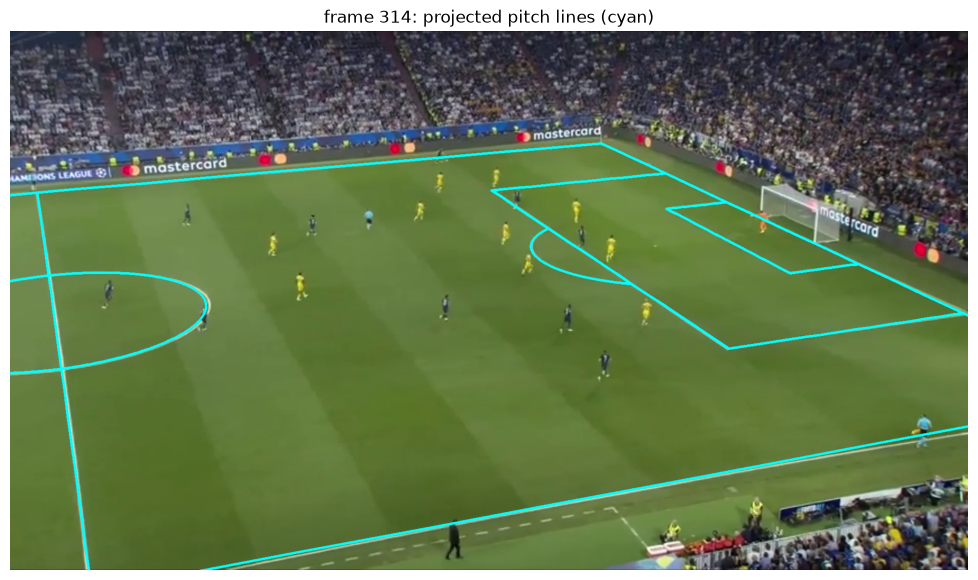

In [3]:
homographies = Homographies()
print(f"{len(homographies.keyframes)} keyframes: {sorted(homographies.keyframes)}")

from pitch import LINES  # noqa: E402

idx = 314  # a frame between two keyframes
frame = cv2.imread(str(frames[frame_ids.index(idx)]))
for line in LINES:
    dense = np.concatenate([np.linspace(a, b, 20) for a, b in zip(line[:-1], line[1:])])
    pts = homographies.pitch_to_image(dense, idx)
    cv2.polylines(frame, [np.clip(pts, -10000, 10000).astype(np.int32)], False, (255, 255, 0), 3)
plt.figure(figsize=(14, 7))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"frame {idx}: projected pitch lines (cyan)")
plt.axis("off")
plt.show()

## 1. Detectie

YOLO op alle 660 frames. Dat duurt op de Arc GPU ±4 minuten (bij 1600–1920 px); het resultaat wordt bewaard in
`output/`, zodat opnieuw draaien (bv. na het aanpassen van een instelling hieronder) maar enkele seconden kost.
Verwijder het cachebestand als je een nieuw model gebruikt.

In [4]:
cache = OUTPUT_DIR / f"detections_{RUN}_{IMGSZ}.json"
if cache.exists():
    detections = {int(k): v for k, v in json.loads(cache.read_text()).items()}
    print("loaded from cache:", cache.name)
else:
    model = YOLO(str(WEIGHTS), task="detect")
    detections = {}
    for n, (idx, path) in enumerate(zip(frame_ids, frames), start=1):
        res = model.predict(cv2.imread(str(path)), imgsz=IMGSZ, conf=DETECT_CONF, device=DEVICE, verbose=False)[0]
        detections[idx] = [{"name": model.names[c], "box": [round(v, 1) for v in b], "conf": round(s, 3)}
                           for c, s, b in zip(res.boxes.cls.int().tolist(), res.boxes.conf.tolist(),
                                              res.boxes.xyxy.tolist())]
        if n % 100 == 0:
            print(f"{n}/{len(frames)} frames")
    cache.write_text(json.dumps(detections))
print("boxes per frame:", {k: round(v / len(detections), 1) for k, v in
                          Counter(d["name"] for ds in detections.values() for d in ds).items()})

Loading c:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CV-Challenge\kobe\notebooks\runs\yolo26l_1920\weights\best_openvino_model for OpenVINO inference...
Using OpenVINO LATENCY mode for batch=1 inference on GPU.0...
100/660 frames
200/660 frames
300/660 frames
400/660 frames
500/660 frames
600/660 frames
boxes per frame: {'player_B_goal_keeper': 1.7, 'referee': 6.4, 'player_B': 20.0, 'player_A': 20.4, 'ball': 0.4}


## 2. Dubbele boxen weg

Het model zet soms twee boxen op één speler, vaak met een ander team (de ene `player_A`, de andere `player_B`).
Dat zou twee stippen op de minimap geven. Van twee persoon-boxen die sterk overlappen (IoU > 0,6) houden we
enkel de zekerste. (YOLO26 doet zelf geen klasse-overschrijdende NMS.)

In [5]:
def iou(a, b):
    w = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def is_person(d):
    return d["name"] in COLOURS


removed = 0
for idx, ds in detections.items():
    kept = [d for d in ds if not is_person(d)]
    for d in sorted(filter(is_person, ds), key=lambda d: -d["conf"]):
        if all(iou(d["box"], k["box"]) <= DUPLICATE_IOU for k in kept if is_person(k)):
            kept.append(d)
        else:
            removed += 1
    detections[idx] = kept
print(f"removed {removed} duplicate boxes ({removed / len(detections):.1f} per frame)")

removed 7047 duplicate boxes (10.7 per frame)


## 3. Tracking: één ID en één team per speler

Per frame apart flikkert alles: een speler is in het ene frame PSG en in het volgende Inter. **ByteTrack** verbindt
de detecties over de tijd:
1. een **Kalman-filter** voorspelt per speler waar zijn box in het volgende frame staat;
2. de nieuwe boxen worden aan die voorspellingen gekoppeld op basis van **overlap (IoU)**: eerst de zekere boxen
   (conf ≥ 0,3), daarna mogen ook zwakke boxen (0,1–0,3) een bestaande speler verder volgen;
3. een speler die even verdwijnt (achter een andere speler) blijft tot 30 frames "onthouden".

Daarna krijgt elke track **één groep via een meerderheidsstem**: de klasse met de hoogste som van confidences over
alle frames van die track. Eén fout frame verandert het team niet meer.

In [6]:
track_people(detections, is_person)
votes = vote_groups(detections, lambda d: d["name"])
agreement = np.array([share for _, share in votes.values()])
print(f"{len(votes)} tracks; agreement on the group within a track: median {np.median(agreement):.0%}, "
      f"{np.sum(agreement < 0.8)} tracks below 80%")

128 tracks; agreement on the group within a track: median 100%, 2 tracks below 80%


## 4. Van beeld naar veld: waar staat iedereen?

De homografie geldt enkel voor punten **op het grasvlak** (vlakke-veld-aanname). Daarom nemen we van elke speler
het midden van de **onderrand** van de box: zijn voeten. Wie meer dan 3 m buiten de lijnen staat (bank,
ballenjongens, fotografen) telt niet mee.

In [7]:
def on_pitch(xy):
    return -PITCH_MARGIN <= xy[0] <= LENGTH + PITCH_MARGIN and -PITCH_MARGIN <= xy[1] <= WIDTH + PITCH_MARGIN


people_per_frame = {}
for idx in frame_ids:
    people = []
    for d in detections[idx]:
        if is_person(d) and d.get("track") is not None:
            x1, y1, x2, y2 = d["box"]
            xy = homographies.image_to_pitch([((x1 + x2) / 2, y2)], idx)[0]  # the feet
            if on_pitch(xy):
                people.append({"group": d["group"], "xy": xy, "box": d["box"], "track": d["track"]})
    people_per_frame[idx] = people

per_group = {g: np.mean([sum(p["group"] == g for p in ps) for ps in people_per_frame.values()]) for g in COLOURS}
print("average on the pitch per frame:", {label(g): round(float(v), 1) for g, v in per_group.items()})

average on the pitch per frame: {'PSG (A)': 10.1, 'Inter (B)': 9.8, 'Inter keeper': 1.1, 'referee': 2.9}


## 5. De bal: filteren en volgen met een Kalman-filter

**Kandidaten.** Elke ball-detectie ≥ 0,1 die klein genoeg is, op het veld ligt en niet op een geschilderde stip.

**Kalman-filter** (in meters op het veld, model met constante snelheid):
- voorspel waar de bal nu moet zijn (positie + snelheid van vorige frames);
- aanvaard enkel een kandidaat **binnen 2 m van die voorspelling** (+1 m per frame dat de bal zoek was);
  een witte schoen ver van de baan van de bal wordt zo genegeerd;
- is de gekoppelde kandidaat zwak (< 0,2) en ligt er elders een zekere bal (≥ 0,45), dan herstarten we daar;
- na 15 frames zonder bal stopt de track; een nieuwe start pas bij een kandidaat ≥ `BALL_START`.

Ontbrekende frames tussen twee metingen (max. 15 = 0,5 s) worden **lineair geïnterpoleerd** op het veld.

ball candidates in 120 frames -> ball detected in 0, interpolated in 0, missing in 660 of 660 frames


TypeError: scatter() missing 2 required positional arguments: 'x' and 'y'

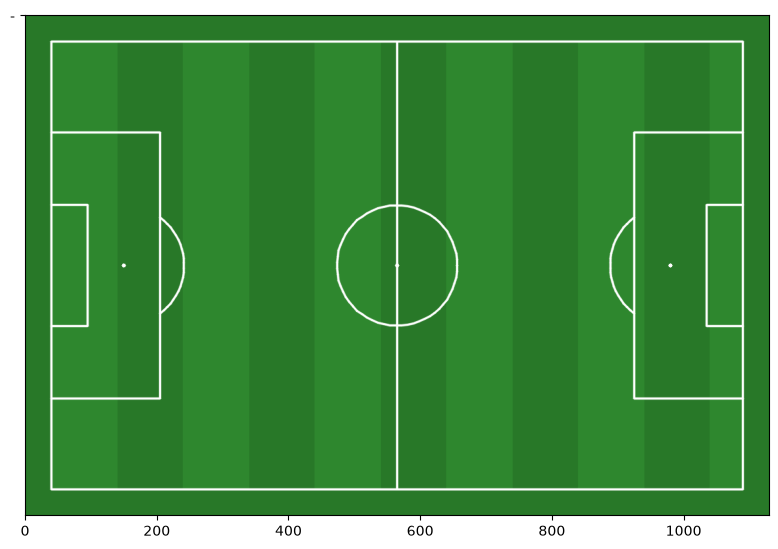

In [8]:
candidates = {}
for idx, ds in detections.items():
    for d in ds:
        if d["name"] != "ball" or d["conf"] < BALL_CONF:
            continue
        x1, y1, x2, y2 = d["box"]
        if max(x2 - x1, y2 - y1) > MAX_BALL_SIZE:
            continue
        xy = homographies.image_to_pitch([((x1 + x2) / 2, (y1 + y2) / 2)], idx)[0]
        if on_pitch(xy) and min(np.hypot(*np.subtract(xy, s)) for s in SPOTS) > SPOT_RADIUS:
            candidates.setdefault(idx, []).append((xy, d["conf"], d["box"]))

ball = track_ball(candidates, frame_ids, MAX_BALL_GAP, start_conf=BALL_START, weak=min(0.2, BALL_START))
n_det = sum(not b[2] for b in ball.values())
print(f"ball candidates in {len(candidates)} frames -> ball detected in {n_det}, "
      f"interpolated in {len(ball) - n_det}, missing in {len(frame_ids) - len(ball)} of {len(frame_ids)} frames")

conf = [c[1] for cs in candidates.values() for c in cs]
print(f"highest ball confidence: {max(conf, default=0):.2f} (a track starts at {BALL_START})")

# The ball's path over the whole clip on the minimap
img = cv2.cvtColor(MINIMAP, cv2.COLOR_BGR2RGB)
pts = [mini_px(ball[i][0]) for i in frame_ids if i in ball] or [(np.nan, np.nan)]
plt.figure(figsize=(10, 6.5))
plt.imshow(img)
plt.plot(*zip(*pts), "-", color="white", lw=1)
plt.scatter(*zip(*pts), c=[i for i in frame_ids if i in ball], cmap="plasma", s=8)
plt.colorbar(label="frame")
plt.title("Path of the ball (colour = time)")
plt.axis("off")
plt.show()

## Controle: klopt de balpositie?

Van de gelabelde frames kennen we de echte plaats van de bal. We vergelijken twee methodes:
- **per frame**: gewoon de zekerste bal in elk frame (zonder tracking);
- **Kalman**: de balvolging hierboven;

telkens per split uit `01_split_images.ipynb`. Alleen de **test**-frames zijn nooit door het model gezien en geven dus een
eerlijk beeld; train-frames zijn te optimistisch. Een bal telt als juist als hij binnen 1,5 m van de echte ligt.

In [ ]:
def frame_split(idx):
    for split in ["train", "val", "test"]:
        if any((NB_DIR.parent / "dataset" / split / "images").glob(f"*_idx_{idx:05d}_*")):
            return split
    return "not used"


truth = {}
for lab in (REPO_ROOT / "data" / "dataset_yolo").glob("*/labels/*.txt"):
    idx = int(re.search(r"idx_(\d+)", lab.name).group(1))
    balls = [list(map(float, l.split()[1:3])) for l in lab.read_text().splitlines() if l.startswith("0 ")]
    truth[idx] = homographies.image_to_pitch([(x * 1920, y * 1080) for x, y in balls], idx)[0] if balls else None

per_frame = {i: (max(c, key=lambda c: c[1])[0], None, False) for i, c in candidates.items()}
print(f"{'split':<9}{'method':<11}{'correct':>8}{'wrong place':>12}{'missed':>8}{'false ball':>12}")
for split in ["train", "val", "test", "not used"]:
    ids = [i for i in truth if frame_split(i) == split]
    if not ids:
        continue
    for method, track in [("per frame", per_frame), ("Kalman", ball)]:
        r = Counter()
        for i in ids:
            if truth[i] is None:
                r["false ball"] += i in track
            elif i not in track:
                r["missed"] += 1
            else:
                r["correct" if np.hypot(*np.subtract(track[i][0], truth[i])) <= 1.5 else "wrong place"] += 1
        print(f"{split:<9}{method:<11}{r['correct']:>8}{r['wrong place']:>12}{r['missed']:>8}{r['false ball']:>12}")

## 6. Balbezit

Per frame: het team van de **dichtste speler binnen 2 m van de bal** (de scheidsrechter telt niet). Om flikkeren
te vermijden verandert het balbezit pas als een ander team de bal **5 frames na elkaar** heeft; na 15 frames
zonder speler bij de bal wordt het "–".

In [ ]:
TEAM_OF = {"player_A": "A", "player_B": "B", "player_B_goal_keeper": "B"}
raw_owner, owner_xy = {}, {}
for idx in frame_ids:
    raw_owner[idx], owner_xy[idx] = None, None
    players = [p for p in people_per_frame[idx] if p["group"] in TEAM_OF]
    if idx in ball and players:
        dist = [np.hypot(*np.subtract(p["xy"], ball[idx][0])) for p in players]
        i = int(np.argmin(dist))
        if dist[i] <= POSSESSION_RADIUS:
            raw_owner[idx], owner_xy[idx] = TEAM_OF[players[i]["group"]], players[i]["xy"]
owner = stable_possession(raw_owner)
with_owner = [owner[i] for i in frame_ids if owner[i]]
share = Counter(with_owner)
print("possession:", {label(t): f"{100 * n / len(with_owner):.0f}%" for t, n in sorted(share.items())},
      f"(of {len(with_owner)} frames)")
print("changes of possession:", sum(1 for a, b in zip(frame_ids, frame_ids[1:])
                                    if owner[a] and owner[b] and owner[a] != owner[b]))

## 7. De video maken

Per frame: infobalk bovenaan (frame, tijd, aantal per groep, keeper ja/nee, bal ja/nee met confidence,
balbezit en het bezit tot nu toe), het beeld met boxen, track-ID's en veldlijnen, en de minimap met de bal,
zijn spoor (laatste 20 frames) en een witte ring rond de speler die de bal heeft. Daarnaast een csv met dezelfde
cijfers per frame, handig voor het verslag.

In [ ]:
out_video = OUTPUT_DIR / f"minimap_{RUN}.mp4"
out_csv = OUTPUT_DIR / f"minimap_{RUN}_frames.csv"
writer, rows, owned = None, [], Counter()
for idx, path in zip(frame_ids, frames):
    if owner[idx]:
        owned[owner[idx]] += 1
    total = sum(owned.values())
    so_far = {t: 100 * n / total for t, n in sorted(owned.items())} if total else {}
    ball_conf = max((c[1] for c in candidates.get(idx, []) if ball.get(idx, (0, None))[1] == c[2]), default=0.0)
    ring = owner_xy[idx] if owner[idx] and raw_owner[idx] == owner[idx] else None
    image = render_frame(cv2.imread(str(path)), idx, frame_ids[-1], homographies, people_per_frame[idx], ball,
                         ball_conf, owner[idx], ring, so_far)
    if writer is None:
        writer = cv2.VideoWriter(str(out_video), cv2.VideoWriter_fourcc(*"mp4v"), FPS, image.shape[1::-1])
    writer.write(image)

    counts = Counter(p["group"] for p in people_per_frame[idx])
    xy = ball[idx][0] if idx in ball else None
    rows.append({"frame": idx, "time_s": round(idx / FPS, 2), **{label(g): counts.get(g, 0) for g in COLOURS},
                 "ball": "none" if idx not in ball else "interpolated" if ball[idx][2] else "detected",
                 "ball_x_m": round(float(xy[0]), 2) if xy is not None else "",
                 "ball_y_m": round(float(xy[1]), 2) if xy is not None else "",
                 "possession": label(owner[idx]) if owner[idx] else ""})
writer.release()
with open(out_csv, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0]))
    w.writeheader()
    w.writerows(rows)
print("video:", out_video)
print("csv  :", out_csv)

## Een frame uit de video

In [ ]:
cap = cv2.VideoCapture(str(out_video))
cap.set(cv2.CAP_PROP_POS_FRAMES, 48)
ok, image = cap.read()
cap.release()
plt.figure(figsize=(18, 7))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Conclusie en beperkingen

*(in te vullen met de cijfers hierboven)*

Bekende beperkingen, om te bespreken:
- **Vlakke-veld-aanname:** een bal in de lucht ligt niet op het grasvlak en wordt te ver van de camera
  geprojecteerd. Spelers projecteren we via hun voeten, die wel op het gras staan.
- **Homografie tussen keyframes** is geïnterpoleerd; waar de camera snel draait of zoomt kan ze afwijken
  (controle: `check_homography.py`).
- **Balbezit** is zo goed als de baldetectie: een gemiste of valse bal geeft fout balbezit.
- **Teams** komen uit het model; de meerderheidsstem per track vangt losse fouten op, maar een speler die de hele
  tijd verkeerd herkend wordt, blijft fout.